# models demo
Fit return models on a `(date, ticker)` panel **without leaking the future**. We build features and labels, show what shuffled K-fold does on pure noise, then fit ridge and LightGBM with purged CV.

In [1]:
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold

from quantskills.data import synthetic_prices, to_wide
from quantskills.features import feature_panel, label_panel
from quantskills.models import (
    DEFAULT_LGB_PARAMS,
    cv_score,
    dropna_xy,
    fit_lgbm_cv,
    panel_ic,
    shap_importance,
)
from quantskills.utils import holdout_date


def training_xy(prices):
    dates = prices.index.get_level_values("date")
    close = to_wide(prices[dates <= holdout_date(dates, 0.3)], "close")
    return dropna_xy(feature_panel(close), label_panel(close, 21))


X, y = training_xy(synthetic_prices(seed=0))
X.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
mom_12_1,-0.0,0.98,-2.15,3.00
mom_6_1,-0.0,0.98,-2.77,3.00
rev_5,0.0,0.98,-3.00,3.00
rev_21,0.0,0.98,-3.00,2.98
lowvol_21,0.0,0.98,-3.00,3.00
lowvol_63,-0.0,0.98,-2.91,2.74
dist_sma50,-0.0,0.98,-2.95,3.00


## Why shuffled K-fold is banned
On a panel with **no signal at all** (`drift_vol=0`), shuffled K-fold still reports a strong IC: neighbouring days share 20 of their 21 label days, so the model sees its test labels in training. Purged CV removes those rows.

In [2]:
Xn, yn = training_xy(synthetic_prices(seed=0, drift_vol=0.0))
params = {**DEFAULT_LGB_PARAMS, "seed": 0}
leaky = []
for tr, te in KFold(4, shuffle=True, random_state=0).split(Xn):  # WRONG for time series: demo only
    b = lgb.train(params, lgb.Dataset(Xn.iloc[tr], yn.iloc[tr]), 100)
    leaky.append(panel_ic(pd.Series(b.predict(Xn.iloc[te]), Xn.index[te]), yn.iloc[te]))
_, rep = fit_lgbm_cv(Xn, yn, max_rounds=100)
pd.DataFrame(
    {"shuffled K-fold (leaks)": leaky, "purged + embargoed": rep["fold_ic"]},
    index=[f"fold {i}" for i in range(1, 5)],
).round(3)

,shuffled K-fold (leaks),purged + embargoed
fold 1,0.302,0.043
fold 2,0.288,0.023
fold 3,0.283,0.054
fold 4,0.287,0.000


## Ridge: choose the penalty by purged CV

In [3]:
pd.Series(
    {
        a: np.mean(cv_score(lambda a=a: Ridge(alpha=a), X, y, n_splits=4, horizon=21))
        for a in (1.0, 100.0, 1e4, 1e6)
    },
    name="mean CV IC",
).round(4)

1.0          0.0219
100.0        0.0228
10000.0      0.0357
1000000.0    0.0301
Name: mean CV IC, dtype: float64

## LightGBM: early stopping per purged fold, then SHAP

fold IC [ 0.071  0.021  0.055 -0.01 ] | rounds per fold [13, 2, 3, 1] -> 2


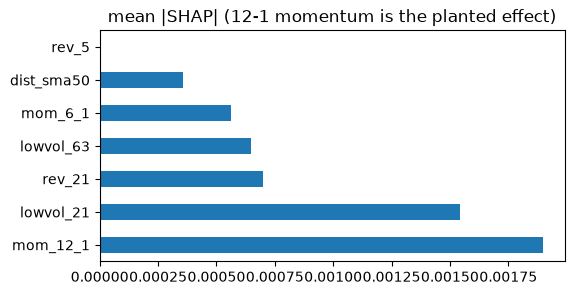

In [4]:
booster, rep = fit_lgbm_cv(X, y, max_rounds=200)
print(
    "fold IC",
    np.round(rep["fold_ic"], 3),
    "| rounds per fold",
    rep["fold_rounds"],
    "->",
    rep["rounds"],
)
shap_importance(booster, X).plot.barh(
    figsize=(6, 3), title="mean |SHAP| (12-1 momentum is the planted effect)"
);

These models are wired into strategies #2 (`linear-forecast`) and #6 (`gbm-long-short`). Their hold-out results are in `strategies/*/README.md`.

## Text: headline tone (strategy #8)
Synthetic headlines whose tone leans towards the next 5-day relative return. A lexicon reads tone from a word list; TF-IDF + logistic learns it from training-window labels. Negated phrases ("fails to beat") trip up word counting without negation handling.

In [5]:
from quantskills.data import news_until, synthetic_prices_with_news
from quantskills.models.text import fit_tfidf, lexicon_score, news_labels, score_headlines

px = synthetic_prices_with_news(seed=0)
d = px.index.get_level_values("date")
train_px = px[d <= holdout_date(d, 0.3)]
news = news_until(train_px)
tfidf = fit_tfidf(news["headline"], news_labels(news, train_px, 5))
examples = pd.Series(
    [
        "ACME beats earnings estimates",
        "ACME fails to beat earnings estimates",
        "ACME faces regulatory probe",
        "ACME schedules annual meeting",
    ]
)
pd.DataFrame(
    {
        "lexicon": [lexicon_score(h) for h in examples],
        "lexicon, no negation": [lexicon_score(h, negation=False) for h in examples],
        "tf-idf": score_headlines(tfidf, examples).round(2),
    },
    index=examples,
)

,lexicon,"lexicon, no negation",tf-idf
ACME beats earnings estimates,1.0,1.0,0.26
ACME fails to beat earnings estimates,-1.0,1.0,-0.25
ACME faces regulatory probe,-1.0,-1.0,-0.46
ACME schedules annual meeting,0.0,0.0,-0.00
